# 04 · Modeling

We build two simple models:

1. **Match result model:** predicts the chance of a home win, draw and away win (Logistic Regression).
2. **Yellow cards model:** predicts how many yellow cards each team gets, based on the referee and the crowd (Linear Regression).

**Important rule: only use what is known before kick-off.**
Goals, shots, fouls and cards happen *during* the match. If we used them to predict the result, the model would already know the answer. This is called **data leakage**. So we only use:
- **Team strength**, calculated from past results (Elo rating)
- **Crowd** (`attendance_pct`: how full the stadium is, 0 = empty, 1 = full)
- **Referee strictness**, calculated from the referee's past matches

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/clean/matches.csv", parse_dates=["date"])
df = df[df["crowd_status"] != "unknown"]
df = df.dropna(subset=["attendance_pct"])
df = df.sort_values(["date", "league", "home_team"]).reset_index(drop=True)
df.shape

(16061, 33)

We drop the `unknown` matches and the 2 matches without a stadium fill value. The data is sorted by date, because the next steps go through matches in order.

## 1. Team strength: Elo rating

Our data doesn't say how strong each team is, so we calculate it with an **Elo rating** (the same idea used to rank chess players):

- Every team starts at **1500**.
- After each match, the winner takes points from the loser.
- Beating a strong team gives more points than beating a weak one.
- A draw moves points from the stronger team to the weaker one.

Each match uses the ratings from **before** that match, so no information from the match itself leaks in.

In [2]:
K = 20          # how fast ratings change after each match
ratings = {}    # (league, team) -> current rating

home_elo = []
away_elo = []

for i, row in df.iterrows():
    home = (row["league"], row["home_team"])
    away = (row["league"], row["away_team"])

    rh = ratings.get(home, 1500)
    ra = ratings.get(away, 1500)
    home_elo.append(rh)
    away_elo.append(ra)

    expected_home = 1 / (1 + 10 ** ((ra - rh) / 400))
    actual_home = {"H": 1, "D": 0.5, "A": 0}[row["result"]]

    ratings[home] = rh + K * (actual_home - expected_home)
    ratings[away] = ra - K * (actual_home - expected_home)

df["home_elo"] = home_elo
df["away_elo"] = away_elo
df["elo_diff"] = df["home_elo"] - df["away_elo"]

**Check: are the ratings sensible?** The strongest teams at the end of our data (May 2026):

In [3]:
final_ratings = pd.DataFrame(
    [(league, team, round(r)) for (league, team), r in ratings.items()],
    columns=["league", "team", "elo"]
)
final_ratings.sort_values("elo", ascending=False).head(10)

,league,team,elo
40,Bundesliga,Bayern Munich,1824
74,La_Liga,Barcelona,1790
84,Serie_A,Inter,1783
8,Ligue_1,Paris SG,1770
20,EPL,Arsenal,1762
77,La_Liga,Real Madrid,1756
23,EPL,Manchester City,1741
65,Serie_A,Napoli,1703
57,Bundesliga,Dortmund,1700
79,Serie_A,Roma,1683


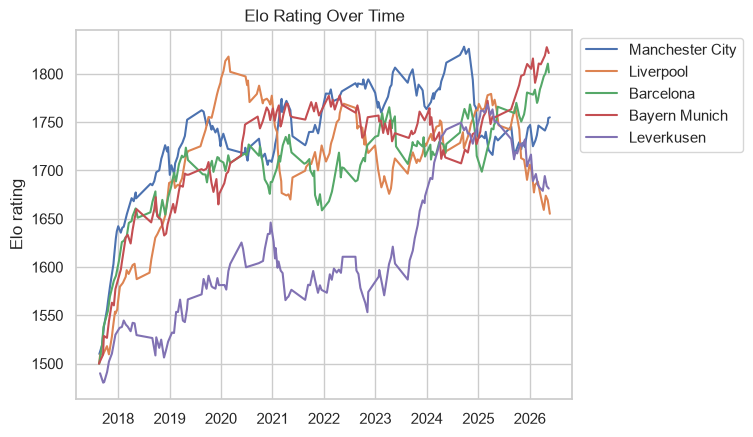

In [4]:
teams = ["Manchester City", "Liverpool", "Barcelona", "Bayern Munich", "Leverkusen"]

for team in teams:
    games = df[(df["home_team"] == team)]
    plt.plot(games["date"], games["home_elo"], label=team)

plt.title("Elo Rating Over Time")
plt.ylabel("Elo rating")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

**Insight:** the ratings follow what really happened. Leverkusen climbs fast in 2023–24, when they won the Bundesliga without losing a match. Manchester City and Bayern stay near the top for most of the period.

The first season (2017–18) is a **warm-up**: every team starts at 1500, so the ratings aren't meaningful yet. We leave it out of the model.

In [5]:
model_df = df[df["season"] >= 2018]
model_df.shape

(14237, 36)

## 2. Model 1: Match result

**Features:** `elo_diff` (home strength − away strength) and `attendance_pct` (crowd).
**Target:** `result` (H / D / A).

We split the data **80% training and 20% testing**. `stratify` keeps the same share of home wins, draws and away wins in both parts.

In [6]:
features = ["elo_diff", "attendance_pct"]

X = model_df[features]
y = model_df["result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (11389, 2)  Test: (2848, 2)


### Baseline

Before training, we need something to compare against. The simplest guess is **"the home team always wins"**.

In [7]:
baseline_acc = (y_test == "H").mean()
print("Baseline accuracy:", round(baseline_acc, 3))

Baseline accuracy: 0.433


### Train the model

In [8]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

Accuracy: 0.525


The model gives a **probability for each result**, not just one answer. For example, the first 5 test matches:

In [9]:
probs = pd.DataFrame(model.predict_proba(X_test), columns=model.classes_) * 100
probs["actual"] = y_test.values
probs.head().round(1)

,A,D,H,actual
0,28.8,27.6,43.6,A
1,12.6,22.0,65.5,A
2,34.9,28.2,36.9,A
3,51.8,26.4,21.8,A
4,20.2,25.4,54.5,D


### Evaluation

In [10]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           A       0.51      0.57      0.54       893
           D       0.00      0.00      0.00       721
           H       0.53      0.80      0.64      1234

    accuracy                           0.52      2848
   macro avg       0.35      0.46      0.39      2848
weighted avg       0.39      0.52      0.45      2848



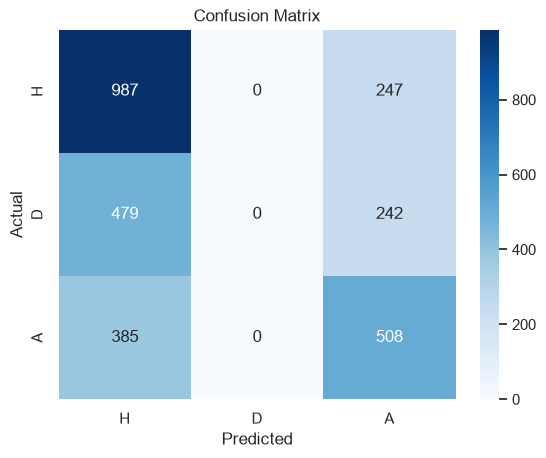

In [11]:
labels = ["H", "D", "A"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Insight:**
- The model beats the baseline by about 9 points.
- It **never predicts a draw**. A draw is rarely the single most likely result, because one team is usually a bit stronger. This is normal in football models. The draw *probability* (around 25–28%) is still useful, and it's what we show on the website.
- Around 52% accuracy sounds low, but football is very random. Even betting companies with far more data are only around 53%.

### Compare feature sets

In [12]:
results = [["Baseline (always home win)", round(baseline_acc, 3)]]

for cols in [["elo_diff"], ["elo_diff", "attendance_pct"]]:
    m = LogisticRegression(max_iter=1000).fit(X_train[cols], y_train)
    acc = accuracy_score(y_test, m.predict(X_test[cols]))
    results.append([" + ".join(cols), round(acc, 3)])

pd.DataFrame(results, columns=["Model", "Accuracy"])

,Model,Accuracy
0,Baseline (always home win),0.433
1,elo_diff,0.524
2,elo_diff + attendance_pct,0.525


**Insight:** team strength does most of the work. Adding the crowd barely changes the overall accuracy, because only about 15% of matches were ghost games. To see what the crowd adds, we have to look at those matches specifically.

### Does the crowd feature help in empty stadiums?

We compare the **average predicted home win %** on the ghost games in the test set, with and without the crowd feature, against what really happened.

In [13]:
ghost_test = X_test[X_test["attendance_pct"] == 0]
ghost_actual = (y_test[ghost_test.index] == "H").mean() * 100

model_no_crowd = LogisticRegression(max_iter=1000).fit(X_train[["elo_diff"]], y_train)
pred_no_crowd = model_no_crowd.predict_proba(ghost_test[["elo_diff"]])[:, 2].mean() * 100
pred_crowd = model.predict_proba(ghost_test)[:, 2].mean() * 100

print("Ghost games in test set:", len(ghost_test))
print("Actual home win %:              ", round(ghost_actual, 1))
print("Predicted, without crowd feature:", round(pred_no_crowd, 1))
print("Predicted, with crowd feature:   ", round(pred_crowd, 1))

Ghost games in test set: 443
Actual home win %:               41.3
Predicted, without crowd feature: 43.8
Predicted, with crowd feature:    41.2


**Insight:** without knowing about the crowd, the model **overestimates** home wins in empty stadiums, because it assumes the normal home advantage. With the crowd feature, its prediction is much closer to what really happened. So the crowd feature makes the model **more realistic**, even if overall accuracy hardly moves.

### How confident is the model?

In [14]:
confidence = model.predict_proba(X_test).max(axis=1)

rows = []
for level in [0.5, 0.6, 0.7]:
    sure = confidence >= level
    acc = accuracy_score(y_test[sure], y_pred[sure])
    rows.append([f"{int(level * 100)}%+", f"{sure.mean() * 100:.0f}%", round(acc, 3)])

pd.DataFrame(rows, columns=["Model confidence", "Share of matches", "Accuracy"])

,Model confidence,Share of matches,Accuracy
0,50%+,50%,0.624
1,60%+,25%,0.694
2,70%+,9%,0.759


**Insight:** when the model is confident, it's usually right. Matches where it gives one result 70%+ are predicted correctly about 3 times out of 4 (76%), compared with 52% overall. The close matches pull the overall accuracy down, and those are hard for anyone to call.

### The crowd effect

Same two teams, equal strength (`elo_diff = 0`). Only the crowd changes:

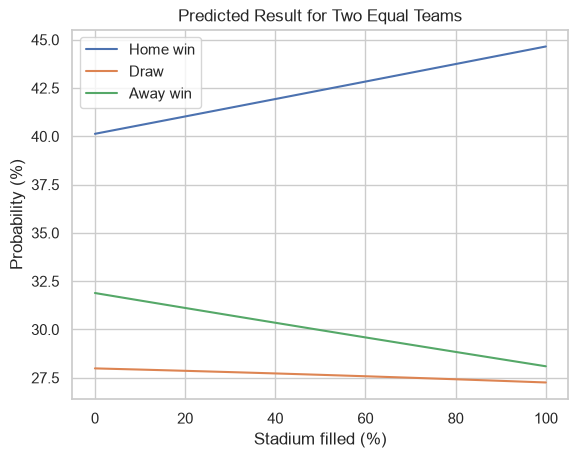

,A,D,H,attendance_pct
0,31.9,28.0,40.1,0.0
5,30.0,27.7,42.4,0.5
10,28.1,27.3,44.7,1.0


In [15]:
crowd_levels = np.linspace(0, 1, 11)
test_input = pd.DataFrame({"elo_diff": 0, "attendance_pct": crowd_levels})
crowd_probs = pd.DataFrame(model.predict_proba(test_input), columns=model.classes_) * 100
crowd_probs["attendance_pct"] = crowd_levels

plt.plot(crowd_probs["attendance_pct"] * 100, crowd_probs["H"], label="Home win")
plt.plot(crowd_probs["attendance_pct"] * 100, crowd_probs["D"], label="Draw")
plt.plot(crowd_probs["attendance_pct"] * 100, crowd_probs["A"], label="Away win")
plt.title("Predicted Result for Two Equal Teams")
plt.xlabel("Stadium filled (%)")
plt.ylabel("Probability (%)")
plt.legend()
plt.show()

crowd_probs.iloc[[0, 5, 10]].round(1)

**Insight:** for two equal teams, the home win chance goes from about **40% in an empty stadium to 45% in a full one**, and the away win chance drops from 32% to 28%. The draw chance barely moves. This matches the EDA: the crowd turns away wins into home wins.

## 3. Model 2: Yellow cards

The EDA showed referees give away teams more yellow cards when there's a crowd. Here we predict how many yellow cards **each team** gets.

**New feature: referee strictness.** Some referees give far more cards than others. For each match, we take the referee's **average cards per match in their previous matches** (so the current match isn't included). Referees need at least 10 past matches.

In [16]:
df["total_yellows"] = df["home_yellows"] + df["away_yellows"]

df["ref_strictness"] = df.groupby("referee")["total_yellows"].transform(
    lambda cards: cards.shift(1).expanding(min_periods=10).mean()
)

cards_df = df[df["season"] >= 2018].dropna(subset=["ref_strictness"])
cards_df.shape

(13182, 38)

In [17]:
ref_avg = df.groupby("referee")["total_yellows"].agg(["mean", "count"])
ref_avg = ref_avg[ref_avg["count"] >= 50].sort_values("mean")

print("Most lenient referees:")
print(ref_avg.head(3).round(2))
print("\nStrictest referees:")
print(ref_avg.tail(3).round(2))

Most lenient referees:
                mean  count
referee                    
Manuel Gräfe    2.53     68
Graham Scott    2.58     93
Andre Marriner  2.73    135

Strictest referees:
                     mean  count
referee                         
Mateo Busquets       5.55     58
Daniel Ask           5.62     80
Alejandro Hernández  5.87    163


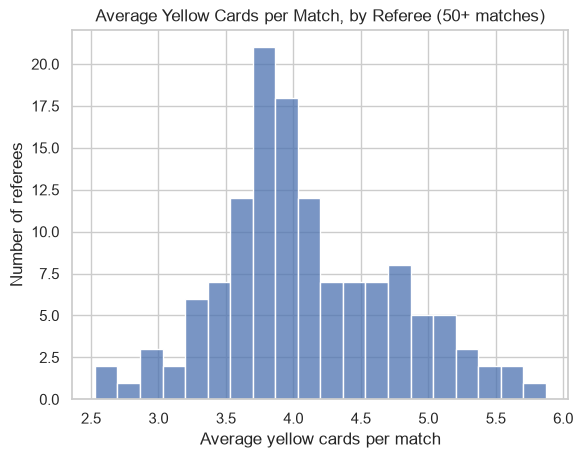

In [18]:
sns.histplot(ref_avg["mean"], bins=20)
plt.title("Average Yellow Cards per Match, by Referee (50+ matches)")
plt.xlabel("Average yellow cards per match")
plt.ylabel("Number of referees")
plt.show()

**Insight:** referees are very different. The most lenient give about 2.5 yellow cards per match, and the strictest almost 6, more than double. So the referee matters a lot for how many cards a match will have.

In [19]:
card_features = ["ref_strictness", "attendance_pct"]

X = cards_df[card_features]
X_train, X_test, idx_train, idx_test = train_test_split(
    X, cards_df.index, test_size=0.2, random_state=42
)

card_models = {}
rows = []
for target in ["home_yellows", "away_yellows"]:
    y_train = cards_df.loc[idx_train, target]
    y_test = cards_df.loc[idx_test, target]

    m = LinearRegression().fit(X_train, y_train)
    pred = m.predict(X_test)
    card_models[target] = m

    baseline_mae = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))
    rows.append([target, round(mean_absolute_error(y_test, pred), 3), round(baseline_mae, 3),
                 round(r2_score(y_test, pred), 3), round(m.coef_[0], 3), round(m.coef_[1], 3)])

pd.DataFrame(rows, columns=["Target", "MAE", "Baseline MAE", "R²", "ref_strictness coef", "attendance_pct coef"])

,Target,MAE,Baseline MAE,R²,ref_strictness coef,attendance_pct coef
0,home_yellows,1.042,1.048,0.062,0.362,-0.039
1,away_yellows,1.065,1.080,0.043,0.360,0.200


**Insight:**
- The errors are only a little better than the baseline, and R² is low. **Exact card counts are hard to predict**, because cards depend on what happens in the match.
- But the **coefficients** tell a clear story:
  - `ref_strictness`: a stricter referee means more cards for **both** teams.
  - `attendance_pct`: a full stadium adds about **0.2 yellow cards to the away team**, and slightly *reduces* the home team's cards. The crowd pushes the referee against the visitors, which is the same result as the EDA.

So we use this model on the website as an **"expected cards"** estimate, not a precise prediction.

In [20]:
avg_ref = cards_df["ref_strictness"].median()
example = pd.DataFrame({"ref_strictness": [avg_ref, avg_ref], "attendance_pct": [0, 1]},
                       index=["Empty stadium", "Full stadium"])

example["home_yellows"] = card_models["home_yellows"].predict(example[card_features])
example["away_yellows"] = card_models["away_yellows"].predict(example[card_features])
example.round(2)

,ref_strictness,attendance_pct,home_yellows,away_yellows
Empty stadium,3.93,0,1.92,1.97
Full stadium,3.93,1,1.88,2.17


## 4. Export for the website

The website runs the models in the browser, so it only needs:
- the model **coefficients** (a few numbers per model)
- the **current Elo rating** of every team in the 2025–26 season
- the **strictness** of every referee who worked in 2025–26

In [21]:
current = df[df["season"] == 2025]

teams_export = {}
for league in current["league"].unique():
    league_teams = sorted(current.loc[current["league"] == league, "home_team"].unique())
    teams_export[league] = {team: round(ratings[(league, team)], 1) for team in league_teams}

refs_now = current.groupby(["league", "referee"]).size().reset_index()[["league", "referee"]]
refs_export = {}
for _, r in refs_now.iterrows():
    games = df[df["referee"] == r["referee"]]
    if len(games) >= 10:
        refs_export.setdefault(r["league"], {})[r["referee"]] = round(games["total_yellows"].mean(), 2)

export = {
    "result_model": {
        "classes": list(model.classes_),
        "features": features,
        "coef": model.coef_.round(5).tolist(),
        "intercept": model.intercept_.round(5).tolist(),
    },
    "cards_model": {
        target: {"features": card_features,
                 "coef": m.coef_.round(5).tolist(),
                 "intercept": round(float(m.intercept_), 5)}
        for target, m in card_models.items()
    },
    "teams": teams_export,
    "referees": refs_export,
}

with open("../data/clean/model_export.json", "w", encoding="utf-8") as f:
    json.dump(export, f, ensure_ascii=False, indent=2)

print("Teams:", sum(len(t) for t in teams_export.values()))
print("Referees:", sum(len(r) for r in refs_export.values()))

Teams: 96
Referees: 116


**Check:** the website will calculate the probabilities by hand from these numbers. We make sure that gives the same answer as scikit-learn, using one test match.

In [22]:
sample = model_df[features].iloc[0]

scores = np.array(export["result_model"]["coef"]) @ sample.values + np.array(export["result_model"]["intercept"])
manual = np.exp(scores) / np.exp(scores).sum()

print("By hand:      ", (manual * 100).round(2))
print("scikit-learn: ", (model.predict_proba(sample.to_frame().T)[0] * 100).round(2))

By hand:       [13.86 22.52 63.62]
scikit-learn:  [13.85 22.51 63.64]


The two match (tiny differences come from rounding the coefficients), so the website will give the same probabilities as the model here.

## 5. Conclusion

**Match result model (Logistic Regression)**
- Accuracy around 52%, about 9 points better than always guessing a home win. That's close to the realistic limit for predicting football.
- Much more reliable when confident: 76% correct when it gives one result 70%+.
- The crowd feature makes predictions realistic in empty stadiums.
- **Crowd effect:** for two equal teams, home win chance rises from about 40% (empty) to 45% (full).

**Yellow cards model (Linear Regression)**
- Exact card counts are hard to predict (low R²).
- The referee is the biggest factor, and a full stadium gives the **away team** about 0.2 more yellow cards.

**Limitations**
- The model never picks a draw as the single most likely result.
- Elo only uses results, not injuries, transfers or new managers.
- The crowd effect is an **average** across all teams. Each team has too few ghost games to measure its own crowd effect.
- Referee strictness needs at least 10 past matches, so new referees are left out.